# Paper-aligned No-Context baseline trên Stanford Cars

Notebook này là bản copy/adapt từ `baseline_no_tacs_image_classification.ipynb`, nhưng phần dataset đã đổi từ CUB-200-2011 sang Stanford Cars trong thư mục `archive (10)`.

Pipeline giữ nguyên tinh thần baseline No-Context: `query image -> DINOv3 ViT-S/16 -> classification head -> class_id 0..195 + tên dòng xe`.

Theo yêu cầu bám **standard split của dataset**, notebook chỉ dùng hai split có sẵn: train và test. Toàn bộ `cars_train_annos.mat` được dùng để train; `cars_test_annos.mat` được dùng làm official test. Lưu ý: trong `archive (10)`, test annotations không có trường `class`, nên notebook không thể tính test accuracy nếu không có thêm file nhãn test.

## 1. Dataset Stanford Cars trong `archive (10)`

Cấu trúc dataset đã đọc được:

```text
archive (10)/
  car_devkit/devkit/
    cars_meta.mat          # 196 tên lớp xe
    cars_train_annos.mat   # 8,144 ảnh train có bbox + class + fname
    cars_test_annos.mat    # 8,041 ảnh test có bbox + fname, không có class trong bản này
  cars_train/cars_train/
    00001.jpg ...
  cars_test/cars_test/
    00001.jpg ...
```

Class ID trong file `.mat` là `1..196`; code chuyển về nhãn mô hình `0..195`. Không tạo validation split tự phát sinh, vì đề yêu cầu dùng standard train/test split của dataset.

In [1]:
# from google.colab import drive
# drive.mount('/content/drive')

In [2]:
!wget -c 'https://dinov3.llamameta.net/dinov3_vits16/dinov3_vits16_pretrain_lvd1689m-08c60483.pth?Policy=eyJTdGF0ZW1lbnQiOlt7InVuaXF1ZV9oYXNoIjoiNTFma3Jxa3l3bTl3MGpweHI2NndvNWZsIiwiUmVzb3VyY2UiOiJodHRwczpcL1wvZGlub3YzLmxsYW1hbWV0YS5uZXRcLyoiLCJDb25kaXRpb24iOnsiRGF0ZUxlc3NUaGFuIjp7IkFXUzpFcG9jaFRpbWUiOjE3ODkyOTc0MTJ9fX1dfQ__&Signature=sdowk%7EiiF6j8599sB9K5-M3sB%7Elq1be-oKP%7El7VBISEmjHEBPyCWw9Y2JD4oJY9LbXE313Q4ZgjX%7EXO3EiwGQZ3MZhfkZr0OXmADX8L%7E7XX%7E4mkVA1JSOkVzEa3Oj39gY%7E%7ER21%7EmJXEcFOZPMj%7EzGs-uxIh1xeRrfo-ZUqv3Yz7z7vUgn1OoDhu98kPnh8KT4MF1Gd6gcB4LogqWk3ooVScR6z8ECw50eawfY8lyUUzv%7E%7Em1QdstSU1k6HFhKFbuuogf0MyH7rzYScskxtGG95ke47CKn6CWSNbHLKhcLDfNx-XrN0A-xxis10rpJaMh2jBmxwohSr8XQlGVCBPWqQ__&Key-Pair-Id=K15QRJLYKIFSLZ&Download-Request-ID=1749739516259745' \
  -O /kaggle/working/dinov3_vits16_pretrain_lvd1689m-08c60483.pth

--2026-09-12 11:20:11--  https://dinov3.llamameta.net/dinov3_vits16/dinov3_vits16_pretrain_lvd1689m-08c60483.pth?Policy=eyJTdGF0ZW1lbnQiOlt7InVuaXF1ZV9oYXNoIjoiNTFma3Jxa3l3bTl3MGpweHI2NndvNWZsIiwiUmVzb3VyY2UiOiJodHRwczpcL1wvZGlub3YzLmxsYW1hbWV0YS5uZXRcLyoiLCJDb25kaXRpb24iOnsiRGF0ZUxlc3NUaGFuIjp7IkFXUzpFcG9jaFRpbWUiOjE3ODkyOTc0MTJ9fX1dfQ__&Signature=sdowk%7EiiF6j8599sB9K5-M3sB%7Elq1be-oKP%7El7VBISEmjHEBPyCWw9Y2JD4oJY9LbXE313Q4ZgjX%7EXO3EiwGQZ3MZhfkZr0OXmADX8L%7E7XX%7E4mkVA1JSOkVzEa3Oj39gY%7E%7ER21%7EmJXEcFOZPMj%7EzGs-uxIh1xeRrfo-ZUqv3Yz7z7vUgn1OoDhu98kPnh8KT4MF1Gd6gcB4LogqWk3ooVScR6z8ECw50eawfY8lyUUzv%7E%7Em1QdstSU1k6HFhKFbuuogf0MyH7rzYScskxtGG95ke47CKn6CWSNbHLKhcLDfNx-XrN0A-xxis10rpJaMh2jBmxwohSr8XQlGVCBPWqQ__&Key-Pair-Id=K15QRJLYKIFSLZ&Download-Request-ID=1749739516259745
Resolving dinov3.llamameta.net (dinov3.llamameta.net)... 99.84.118.47, 99.84.118.60, 99.84.118.8, ...
Connecting to dinov3.llamameta.net (dinov3.llamameta.net)|99.84.118.47|:443... connected.
HTTP request sent, await

In [3]:
from pathlib import Path
import torch

weight_path = Path(
    "/kaggle/working/dinov3_vits16_pretrain_lvd1689m-08c60483.pth"
)

print("Dung lượng:", weight_path.stat().st_size / 1024**2, "MB")

assert weight_path.stat().st_size > 10 * 1024 * 1024, \
    "File vẫn bị rỗng hoặc tải lỗi"

checkpoint = torch.load(
    weight_path,
    map_location="cpu",
    weights_only=True
)

print("Tải checkpoint thành công")
print(type(checkpoint))

Dung lượng: 82.52245235443115 MB
Tải checkpoint thành công
<class 'collections.OrderedDict'>


In [4]:
# !unzip -q /content/drive/MyDrive/archive\ \(13\).zip -d /content/archive\ \(13\)

In [5]:
%pip -q install torch torchvision scipy scikit-learn matplotlib seaborn pandas pillow tqdm torchmetrics

import json
import random
import subprocess
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from PIL import Image
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from tqdm.auto import tqdm

SEED = 44
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__)
print('Device:', DEVICE)

Note: you may need to restart the kernel to use updated packages.
PyTorch: 2.10.0+cu128
Device: cuda


## 2. Cấu hình thí nghiệm

Notebook vẫn dùng backbone `dinov3_vits16` như bản baseline trước. Phần dataset chuyển sang Stanford Cars `.mat` annotations, `NUM_CLASSES` là 196, và output folder là `outputs/baseline_no_tacs_cars`.

`DATASET_ROOT` được dò theo nhiều vị trí để chạy được cả trong workspace local và Colab/Drive nếu bạn copy dataset sang đó.

In [6]:
PROJECT_DIR = Path.cwd()
DATASET_ROOT_CANDIDATES = [
    PROJECT_DIR / '/kaggle/input/datasets/jutrera/stanford-car-dataset-by-classes-folder',
    Path('/kaggle/input/datasets/jutrera/stanford-car-dataset-by-classes-folder'),
    Path('/kaggle/input/datasets/jutrera/stanford-car-dataset-by-classes-folder'),
    Path(r'F:\Documents\CODE\Python\cv_project\XLA\archive (13)'),
]

DATASET_ROOT = next(
    (p for p in DATASET_ROOT_CANDIDATES if (p / 'anno_train.csv').is_file()),
    DATASET_ROOT_CANDIDATES[0],
)

CAR_DATA_ROOT = DATASET_ROOT / 'car_data' / 'car_data'
TRAIN_IMAGE_ROOT = CAR_DATA_ROOT / 'train'
TEST_IMAGE_ROOT = CAR_DATA_ROOT / 'test'
NAMES_CSV = DATASET_ROOT / 'names.csv'
TRAIN_CSV = DATASET_ROOT / 'anno_train.csv'
TEST_CSV = DATASET_ROOT / 'anno_test.csv'

OUTPUT_DIR = PROJECT_DIR / 'outputs' / 'baseline_no_tacs_cars'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DINOV3_REPO_URL = 'https://github.com/facebookresearch/dinov3.git'
DINOV3_REPO_DIR = str(PROJECT_DIR / 'dinov3')
DINOV3_MODEL_NAME = 'dinov3_vits16'
DINOV3_WEIGHTS_URL = 'https://dl.fbaipublicfiles.com/dinov3/dinov3_vits16/dinov3_vits16_pretrain_lvd1689m-08c60483.pth'
DINOV3_WEIGHTS = str(PROJECT_DIR / 'dinov3_vits16_pretrain_lvd1689m-08c60483.pth')

BACKBONE_NAME = DINOV3_MODEL_NAME
FEATURE_DIM = 384
IMAGE_SIZE = 256
BATCH_SIZE = 64
EPOCHS = 100
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 4
NUM_CLASSES = 196
TOP_K = 5
USE_BBOX_CROP = False

print('DATASET_ROOT:', DATASET_ROOT.resolve())
print('TRAIN_IMAGE_ROOT:', TRAIN_IMAGE_ROOT.resolve())
print('TEST_IMAGE_ROOT:', TEST_IMAGE_ROOT.resolve())
print('OUTPUT_DIR:', OUTPUT_DIR.resolve())

DATASET_ROOT: /kaggle/input/datasets/jutrera/stanford-car-dataset-by-classes-folder
TRAIN_IMAGE_ROOT: /kaggle/input/datasets/jutrera/stanford-car-dataset-by-classes-folder/car_data/car_data/train
TEST_IMAGE_ROOT: /kaggle/input/datasets/jutrera/stanford-car-dataset-by-classes-folder/car_data/car_data/test
OUTPUT_DIR: /kaggle/working/outputs/baseline_no_tacs_cars


## 3. Transform và standard train/test split

Stanford Cars bản này đã có train/test split riêng. Notebook giữ đúng split đó:

- Train: `cars_train_annos.mat` + ảnh trong `cars_train/cars_train`.
- Test: `cars_test_annos.mat` + ảnh trong `cars_test/cars_test`.

Do test annotations không có nhãn trong `archive (10)`, test loader sẽ trả về `(image, fname)` để xuất file dự đoán. Không tách validation từ train.

In [7]:
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomResizedCrop((IMAGE_SIZE, IMAGE_SIZE), scale=(0.75, 1.0)),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std),
])

class_names = pd.read_csv(NAMES_CSV, header=None)[0].astype(str).tolist()
NUM_CLASSES = len(class_names)

def read_annotation_csv(csv_path):
    df = pd.read_csv(
        csv_path,
        header=None,
        names=['fname', 'bbox_x1', 'bbox_y1', 'bbox_x2', 'bbox_y2', 'class_id_1based'],
    )
    df['class_id'] = df['class_id_1based'].astype(int) - 1
    df['car_name'] = df['class_id'].map(lambda i: class_names[int(i)])
    return df

def build_image_lookup(image_root):
    image_root = Path(image_root)
    paths = sorted(image_root.rglob('*.jpg'))
    lookup = {}
    duplicates = []
    for path in paths:
        if path.name in lookup:
            duplicates.append(path.name)
        lookup[path.name] = path
    if duplicates:
        raise ValueError(f'Trùng tên ảnh trong {image_root}: {duplicates[:5]}')
    return lookup

def attach_image_paths(df, image_root):
    lookup = build_image_lookup(image_root)
    missing = [fname for fname in df['fname'] if fname not in lookup]
    if missing:
        raise FileNotFoundError(f'Thiếu ảnh, ví dụ: {missing[:5]}')
    out = df.copy()
    out['image_path'] = [str(lookup[fname]) for fname in out['fname']]
    return out

class StanfordCarsCsvDataset(Dataset):
    def __init__(self, annotations, transform, crop_bbox=False):
        self.annotations = annotations.reset_index(drop=True).copy()
        self.transform = transform
        self.crop_bbox = crop_bbox

    def __len__(self):
        return len(self.annotations)

    def __getitem__(self, index):
        row = self.annotations.iloc[index]
        image = Image.open(row['image_path']).convert('RGB')

        if self.crop_bbox:
            left = max(0, int(row['bbox_x1']) - 1)
            top = max(0, int(row['bbox_y1']) - 1)
            right = int(row['bbox_x2'])
            bottom = int(row['bbox_y2'])
            image = image.crop((left, top, right, bottom))

        image = self.transform(image)
        target = int(row['class_id'])
        return image, target

train_df = attach_image_paths(read_annotation_csv(TRAIN_CSV), TRAIN_IMAGE_ROOT)
test_df = attach_image_paths(read_annotation_csv(TEST_CSV), TEST_IMAGE_ROOT)

train_dataset = StanfordCarsCsvDataset(train_df, train_transform, crop_bbox=USE_BBOX_CROP)
test_dataset = StanfordCarsCsvDataset(test_df, eval_transform, crop_bbox=USE_BBOX_CROP)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())

PREDICT_IMAGE = test_df.iloc[0]['image_path']

print('Classes:', NUM_CLASSES)
print(f'Standard train images: {len(train_dataset):,}')
print(f'Standard test images: {len(test_dataset):,}')
print(f'Train label range: {train_df.class_id.min()}..{train_df.class_id.max()}')
print(f'Test label range: {test_df.class_id.min()}..{test_df.class_id.max()}')

display(train_df.head())
display(test_df.head())

Classes: 196
Standard train images: 8,144
Standard test images: 8,041
Train label range: 0..195
Test label range: 0..195


,fname,bbox_x1,bbox_y1,bbox_x2,bbox_y2,class_id_1based,class_id,car_name,image_path
0,00001.jpg,39,116,569,375,14,13,Audi TTS Coupe 2012,/kaggle/input/datasets/jutrera/stanford-car-da...
1,00002.jpg,36,116,868,587,3,2,Acura TL Sedan 2012,/kaggle/input/datasets/jutrera/stanford-car-da...
2,00003.jpg,85,109,601,381,91,90,Dodge Dakota Club Cab 2007,/kaggle/input/datasets/jutrera/stanford-car-da...
3,00004.jpg,621,393,1484,1096,134,133,Hyundai Sonata Hybrid Sedan 2012,/kaggle/input/datasets/jutrera/stanford-car-da...
4,00005.jpg,14,36,133,99,106,105,Ford F-450 Super Duty Crew Cab 2012,/kaggle/input/datasets/jutrera/stanford-car-da...


,fname,bbox_x1,bbox_y1,bbox_x2,bbox_y2,class_id_1based,class_id,car_name,image_path
0,00001.jpg,30,52,246,147,181,180,Suzuki Aerio Sedan 2007,/kaggle/input/datasets/jutrera/stanford-car-da...
1,00002.jpg,100,19,576,203,103,102,Ferrari 458 Italia Convertible 2012,/kaggle/input/datasets/jutrera/stanford-car-da...
2,00003.jpg,51,105,968,659,145,144,Jeep Patriot SUV 2012,/kaggle/input/datasets/jutrera/stanford-car-da...
3,00004.jpg,67,84,581,407,187,186,Toyota Camry Sedan 2012,/kaggle/input/datasets/jutrera/stanford-car-da...
4,00005.jpg,140,151,593,339,185,184,Tesla Model S Sedan 2012,/kaggle/input/datasets/jutrera/stanford-car-da...


,class_id,car_name,count
0,0,AM General Hummer SUV 2000,45
1,1,Acura RL Sedan 2012,32
2,2,Acura TL Sedan 2012,43
3,3,Acura TL Type-S 2008,42
4,4,Acura TSX Sedan 2012,41
...,...,...,...
191,191,Volkswagen Beetle Hatchback 2012,43
192,192,Volvo C30 Hatchback 2012,42
193,193,Volvo 240 Sedan 1993,46
194,194,Volvo XC90 SUV 2007,43


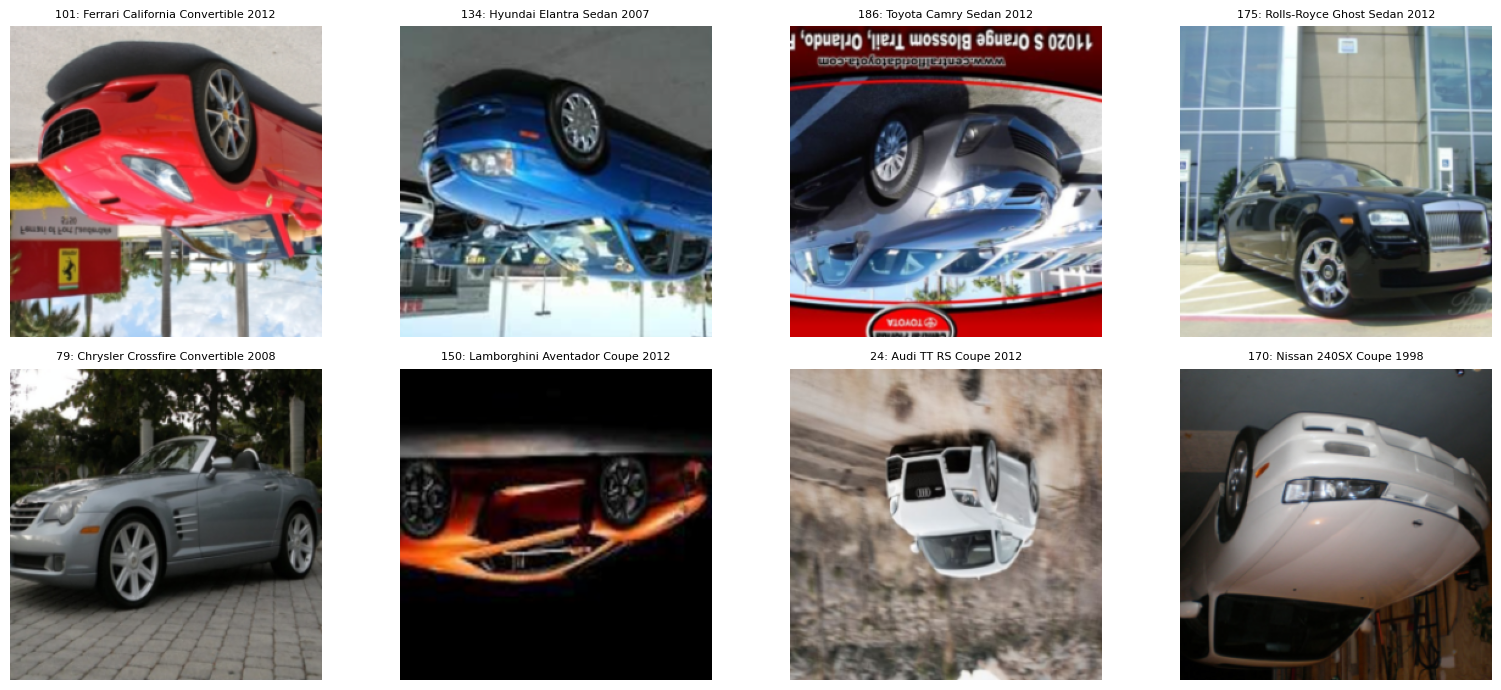

In [8]:
class_counts = train_df['class_id'].value_counts().sort_index()
class_count_df = pd.DataFrame({
    'class_id': class_counts.index,
    'car_name': [class_names[i] for i in class_counts.index],
    'count': class_counts.values,
})
display(class_count_df)

sample_images, sample_labels = next(iter(train_loader))
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for image_tensor, label, ax in zip(sample_images[:8], sample_labels[:8], axes.flat):
    image = image_tensor.permute(1, 2, 0).numpy() * np.asarray(imagenet_std) + np.asarray(imagenet_mean)
    ax.imshow(np.clip(image, 0, 1))
    ax.set_title(f'{int(label)}: {class_names[int(label)]}', fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 4. Kiểm tra hoặc tải DINOv3 assets

Cell này chuẩn bị repo DINOv3 và checkpoint ViT-S/16. Nếu máy đã có file weight, hãy đặt `DINOV3_WEIGHTS` trong cell cấu hình trỏ tới file đó. Nếu chưa có, cell này sẽ thử clone repo DINOv3 và tải checkpoint về workspace hiện tại.

In [9]:
def ensure_dinov3_assets():
    repo_dir = Path(DINOV3_REPO_DIR)
    weights_path = Path(DINOV3_WEIGHTS)

    if not repo_dir.is_dir():
        try:
            print('Cloning DINOv3 repo to:', repo_dir)
            subprocess.run(['git', 'clone', '--depth', '1', DINOV3_REPO_URL, str(repo_dir)], check=True)
        except Exception as exc:
            print('Không clone được DINOv3 repo. torch.hub sẽ thử tải từ GitHub khi tạo model.')
            print(type(exc).__name__ + ':', exc)
    else:
        print('DINOv3 repo đã tồn tại:', repo_dir)

    if not weights_path.is_file():
        print('Đang tải DINOv3 ViT-S/16 weights về:', weights_path)
        urlretrieve(DINOV3_WEIGHTS_URL, weights_path)
    else:
        print('DINOv3 weights đã tồn tại:', weights_path)

    if weights_path.stat().st_size < 10 * 1024 * 1024:
        raise ValueError(f'File weight có vẻ bị lỗi hoặc quá nhỏ: {weights_path}')

    print('Weights size MB:', round(weights_path.stat().st_size / 1024**2, 2))

ensure_dinov3_assets()

Cloning DINOv3 repo to: /kaggle/working/dinov3


Cloning into '/kaggle/working/dinov3'...


DINOv3 weights đã tồn tại: /kaggle/working/dinov3_vits16_pretrain_lvd1689m-08c60483.pth
Weights size MB: 82.52


## 5. Mô hình baseline ViT không TACS

Baseline dùng backbone `dinov3_vits16`, lấy CLS embedding 384 chiều từ DINOv3 ViT-S/16 rồi thêm classification head 196 lớp cho Stanford Cars. Toàn bộ backbone và head được fine-tune bằng AdamW; không có Selector, retrieval hoặc context fusion.

In [10]:

class DinoV3NoContextClassifier(nn.Module):
    def __init__(self, repo_dir, model_name, weights, num_classes, feature_dim=384):
        super().__init__()
        repo_dir = Path(repo_dir)
        source = 'local' if repo_dir.is_dir() else 'github'
        repo_or_dir = str(repo_dir) if repo_dir.is_dir() else 'facebookresearch/dinov3'
        self.backbone = torch.hub.load(repo_or_dir, model_name, source=source, weights=weights)
        self.head = nn.Linear(feature_dim, num_classes)

    def forward(self, images):
        features = self.backbone(images)
        if isinstance(features, dict):
            features = features['x_norm_clstoken']
        return self.head(features)

def resolve_dinov3_weights():
    path = Path(DINOV3_WEIGHTS)

    if not path.is_file():
        raise FileNotFoundError(f"Không tìm thấy file: {path}")

    if path.stat().st_size < 10 * 1024 * 1024:
        raise ValueError("File weight bị rỗng hoặc bị hỏng")

    return str(path)

def create_paper_vit_s16():
    network = DinoV3NoContextClassifier(
        repo_dir=DINOV3_REPO_DIR,
        model_name=DINOV3_MODEL_NAME,
        weights=resolve_dinov3_weights(),
        num_classes=NUM_CLASSES,
        feature_dim=FEATURE_DIM,
    )
    print(f'Loaded DINOv3 backbone: {DINOV3_MODEL_NAME}')
    print(f'DINOv3 weights: {resolve_dinov3_weights()}')
    return network

model = create_paper_vit_s16().to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
checkpoint_path = OUTPUT_DIR / 'final_no_context_dinov3_vits16_cars.pt'
print(model)

Downloading: "file:///kaggle/working/dinov3_vits16_pretrain_lvd1689m-08c60483.pth" to /root/.cache/torch/hub/checkpoints/dinov3_vits16_pretrain_lvd1689m-08c60483.pth


100%|██████████| 82.5M/82.5M [00:00<00:00, 1.39GB/s]

Loaded DINOv3 backbone: dinov3_vits16
DINOv3 weights: /kaggle/working/dinov3_vits16_pretrain_lvd1689m-08c60483.pth


DinoV3NoContextClassifier(
  (backbone): DinoVisionTransformer(
    (patch_embed): PatchEmbed(
      (proj): Conv2d(3, 384, kernel_size=(16, 16), stride=(16, 16))
      (norm): Identity()
    )
    (rope_embed): RopePositionEmbedding()
    (blocks): ModuleList(
      (0-11): 12 x SelfAttentionBlock(
        (norm1): LayerNorm((384,), eps=1e-05, elementwise_affine=True)
        (attn): SelfAttention(
          (qkv): LinearKMaskedBias(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (ls1): LayerScale()
        (norm2): LayerNorm((384,), eps=1e-05, elementwise_affine=True)
        (mlp): Mlp(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout

## 6. Training

Notebook train trên **toàn bộ standard train split** của Stanford Cars (`cars_train_annos.mat`). Không dùng validation split, không early stopping, không chọn checkpoint theo validation. Sau khi train xong, checkpoint cuối cùng được dùng để dự đoán trên standard test split.

In [11]:
def train_one_epoch(network, loader):
    network.train()
    total_loss = 0.0
    all_targets, all_predictions = [], []
    for images, targets in tqdm(loader, leave=False):
        images, targets = images.to(DEVICE), targets.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        logits = network(images)
        loss = criterion(logits, targets)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(network.parameters(), max_norm=1.0)
        optimizer.step()
        total_loss += loss.item() * images.size(0)
        all_targets.extend(targets.detach().cpu().numpy())
        all_predictions.extend(logits.argmax(dim=1).detach().cpu().numpy())
    return {
        'loss': total_loss / len(loader.dataset),
        'accuracy': float(np.mean(np.asarray(all_targets) == np.asarray(all_predictions))),
    }

history = []
for epoch in range(1, EPOCHS + 1):
    train_metrics = train_one_epoch(model, train_loader)
    scheduler.step()
    history.append({
        'epoch': epoch,
        'train_loss': train_metrics['loss'],
        'train_accuracy': train_metrics['accuracy'],
        'learning_rate': scheduler.get_last_lr()[0],
    })
    print(
        f"Epoch {epoch:03d}/{EPOCHS} | "
        f"train loss {train_metrics['loss']:.4f} | "
        f"train top-1 accuracy {train_metrics['accuracy']:.4f} | "
        f"lr {scheduler.get_last_lr()[0]:.2e}"
    )

torch.save({
    'model_state_dict': model.state_dict(),
    'class_names': class_names,
    'architecture': BACKBONE_NAME,
    'feature_dim': FEATURE_DIM,
    'dinov3_model_name': DINOV3_MODEL_NAME,
    'dinov3_repo_dir': DINOV3_REPO_DIR,
    'dinov3_weights': resolve_dinov3_weights(),
    'dataset': 'Stanford Cars',
    'dataset_root': str(DATASET_ROOT),
    'standard_train_size': len(train_dataset),
    'standard_test_size': len(test_dataset),
    'official_test_has_labels': bool('class_id' in test_df.columns),
    'image_size': IMAGE_SIZE,
    'mean': imagenet_mean,
    'std': imagenet_std,
    'epochs': EPOCHS,
    'batch_size': BATCH_SIZE,
    'seed': SEED,
    'use_bbox_crop': USE_BBOX_CROP,
    'pretraining': 'DINOv3',
}, checkpoint_path)
history_df = pd.DataFrame(history)
history_df.to_csv(OUTPUT_DIR / 'training_history.csv', index=False)
print('Saved:', checkpoint_path.resolve())

  0%|          | 0/128 [00:00<?, ?it/s]

Epoch 001/100 | train loss 5.0213 | train top-1 accuracy 0.0681 | lr 1.00e-04


  0%|          | 0/128 [00:00<?, ?it/s]

Epoch 002/100 | train loss 4.1453 | train top-1 accuracy 0.3405 | lr 9.99e-05


  0%|          | 0/128 [00:00<?, ?it/s]

Epoch 003/100 | train loss 3.2938 | train top-1 accuracy 0.5847 | lr 9.98e-05


... (198 outputs left out)

Epoch 099/100 | train loss 0.0031 | train top-1 accuracy 0.9980 | lr 2.47e-08


  0%|          | 0/128 [00:00<?, ?it/s]

IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out


Epoch 100/100 | train loss 0.0034 | train top-1 accuracy 0.9980 | lr 0.00e+00
Saved: /kaggle/working/outputs/baseline_no_tacs_cars/final_no_context_dinov3_vits16_cars.pt


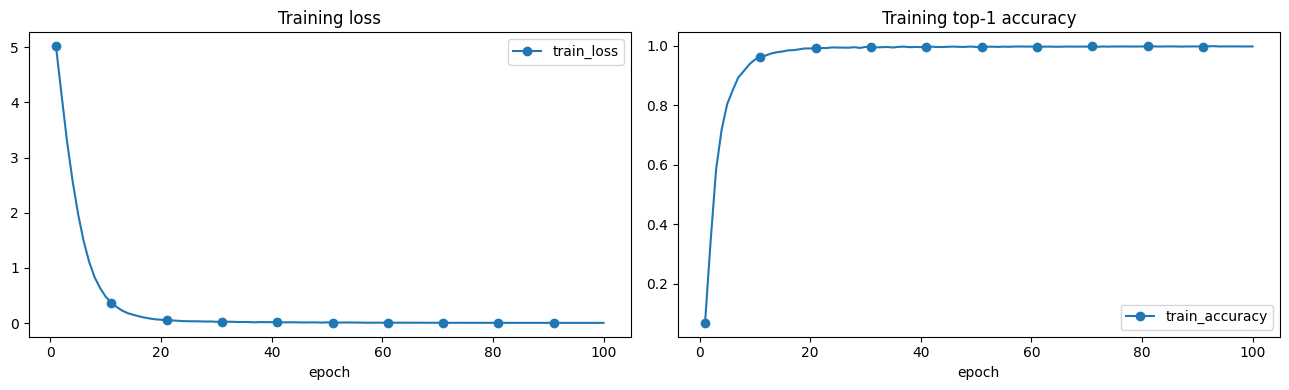

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
history_df.plot(x='epoch', y='train_loss', ax=axes[0], marker='o', markevery=max(1, len(history_df) // 10), title='Training loss')
history_df.plot(x='epoch', y='train_accuracy', ax=axes[1], marker='o', markevery=max(1, len(history_df) // 10), title='Training top-1 accuracy')
plt.tight_layout()
plt.show()

## 7. Official test prediction

Standard test split trong `archive (10)` không có nhãn, nên không thể tính `test_top1_accuracy` hoặc confusion matrix trực tiếp. Cell này chạy model trên toàn bộ `cars_test/cars_test` và lưu file `official_test_predictions.csv` gồm tên ảnh, class dự đoán, tên dòng xe và xác suất.

  0%|          | 0/126 [00:00<?, ?it/s]

Test top-1 accuracy: 0.9159
Test macro-F1 supplementary: 0.9143


,precision,recall,f1-score,support
AM General Hummer SUV 2000,0.976744,0.954545,0.965517,44.0
Acura RL Sedan 2012,0.896552,0.812500,0.852459,32.0
Acura TL Sedan 2012,0.872340,0.953488,0.911111,43.0
Acura TL Type-S 2008,0.954545,1.000000,0.976744,42.0
Acura TSX Sedan 2012,0.945946,0.875000,0.909091,40.0


,fname,true_class_id,true_car_name,predicted_class_id,predicted_car_name,confidence
0,00001.jpg,180,Suzuki Aerio Sedan 2007,180,Suzuki Aerio Sedan 2007,0.999536
1,00002.jpg,102,Ferrari 458 Italia Convertible 2012,102,Ferrari 458 Italia Convertible 2012,0.999645
2,00003.jpg,144,Jeep Patriot SUV 2012,144,Jeep Patriot SUV 2012,0.999329
3,00004.jpg,186,Toyota Camry Sedan 2012,186,Toyota Camry Sedan 2012,0.999571
4,00005.jpg,184,Tesla Model S Sedan 2012,184,Tesla Model S Sedan 2012,0.999139


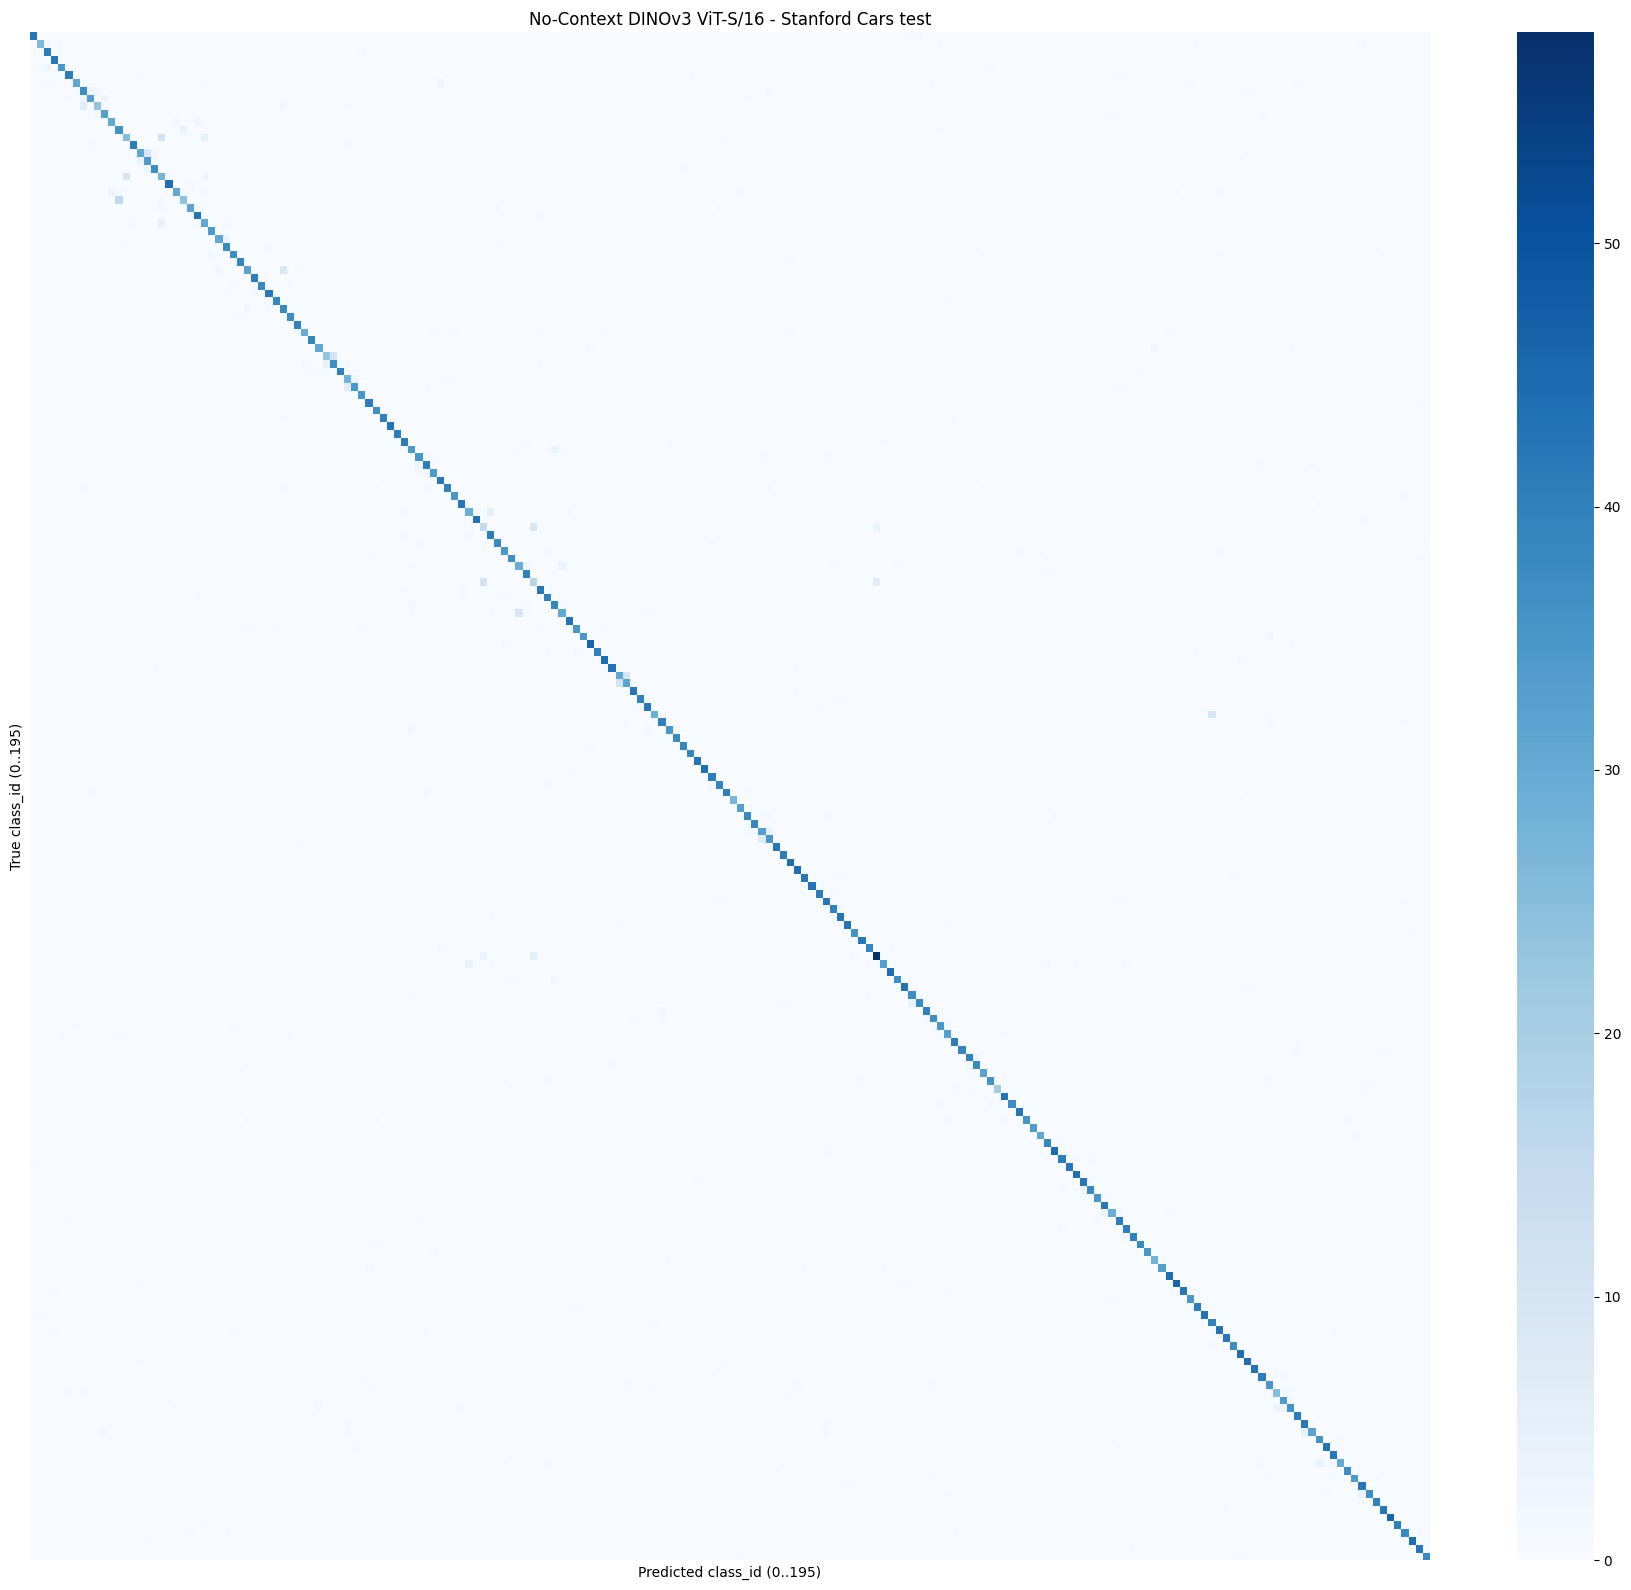

In [13]:
model.load_state_dict(torch.load(checkpoint_path, map_location=DEVICE)['model_state_dict'])
model.eval()

def predict_labeled_loader(network, loader):
    targets, predictions, probabilities = [], [], []
    with torch.inference_mode():
        for images, batch_targets in tqdm(loader, leave=False):
            logits = network(images.to(DEVICE))
            probs = torch.softmax(logits, dim=1).cpu().numpy()
            probabilities.append(probs)
            targets.extend(batch_targets.numpy())
            predictions.extend(probs.argmax(axis=1))
    return np.asarray(targets), np.asarray(predictions), np.concatenate(probabilities)

y_true, y_pred, y_prob = predict_labeled_loader(model, test_loader)

test_top1_accuracy = accuracy_score(y_true, y_pred)
test_macro_f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)

print(f'Test top-1 accuracy: {test_top1_accuracy:.4f}')
print(f'Test macro-F1 supplementary: {test_macro_f1:.4f}')

report = classification_report(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)
report_df = pd.DataFrame(report).T
report_df.to_csv(OUTPUT_DIR / 'test_classification_report.csv')

test_prediction_df = pd.DataFrame({
    'fname': test_df['fname'].to_numpy(),
    'true_class_id': y_true,
    'true_car_name': [class_names[int(i)] for i in y_true],
    'predicted_class_id': y_pred,
    'predicted_car_name': [class_names[int(i)] for i in y_pred],
    'confidence': y_prob.max(axis=1),
})
test_prediction_df.to_csv(OUTPUT_DIR / 'test_predictions.csv', index=False)

display(report_df.head())
display(test_prediction_df.head())

cm = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES))
plt.figure(figsize=(18, 16))
sns.heatmap(cm, cmap='Blues', xticklabels=False, yticklabels=False)
plt.xlabel('Predicted class_id (0..195)')
plt.ylabel('True class_id (0..195)')
plt.title('No-Context DINOv3 ViT-S/16 - Stanford Cars test')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'test_confusion_matrix.png', dpi=160)
plt.show()

with open(OUTPUT_DIR / 'metrics.json', 'w', encoding='utf-8') as file:
    json.dump({
        'test_top1_accuracy': float(test_top1_accuracy),
        'test_macro_f1_supplementary': float(test_macro_f1),
        'num_classes': NUM_CLASSES,
        'standard_train_size': len(train_dataset),
        'standard_test_size': len(test_dataset),
        'architecture': BACKBONE_NAME,
        'pretraining': 'DINOv3',
        'image_size': IMAGE_SIZE,
        'batch_size': BATCH_SIZE,
        'epochs': EPOCHS,
        'seed': SEED,
        'use_bbox_crop': USE_BBOX_CROP,
    }, file, ensure_ascii=False, indent=2)

## 8. Dự đoán tên xe và class_id cho một ảnh

Hàm inference trả về `class_id` trong khoảng `0..195`, tên dòng xe tương ứng và xác suất. Ví dụ `PREDICT_IMAGE` mặc định là ảnh `00001.jpg` trong `cars_train/cars_train`.

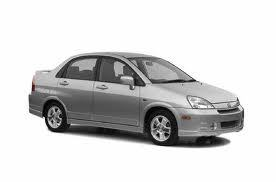

Predicted class_id: 180
Predicted car name: Suzuki Aerio Sedan 2007


,class_id,car_name,probability
0,180,Suzuki Aerio Sedan 2007,99.9536%
1,66,Chevrolet Malibu Hybrid Sedan 2010,0.0108%
2,43,Bentley Continental Flying Spur Sedan 2007,0.0056%
3,114,Ford Focus Sedan 2007,0.0046%
4,187,Toyota Corolla Sedan 2012,0.0018%


In [14]:
def predict_one_image(image_path, network=model, top_k=TOP_K):
    image_path = Path(image_path)
    if not image_path.is_file():
        raise FileNotFoundError(f'Không tìm thấy ảnh: {image_path.resolve()}')
    image = Image.open(image_path).convert('RGB')
    tensor = eval_transform(image).unsqueeze(0).to(DEVICE)
    network.eval()
    with torch.no_grad():
        probabilities = torch.softmax(network(tensor), dim=1)[0]
    top_k = min(top_k, NUM_CLASSES)
    values, indices = torch.topk(probabilities, k=top_k)
    result = pd.DataFrame({
        'class_id': [int(index) for index in indices.cpu()],
        'car_name': [class_names[int(index)] for index in indices.cpu()],
        'probability': values.cpu().numpy(),
    })
    display(image)
    print(f"Predicted class_id: {result.iloc[0]['class_id']}")
    print(f"Predicted car name: {result.iloc[0]['car_name']}")
    display(result.style.format({'probability': '{:.4%}'}))
    return result

# Sửa PREDICT_IMAGE nếu muốn dự đoán ảnh khác.
prediction = predict_one_image(PREDICT_IMAGE)

## 9. Tải checkpoint và dự đoán ở phiên chạy khác

Checkpoint `outputs/baseline_no_tacs_cars/final_no_context_dinov3_vits16_cars.pt` lưu weights của wrapper DINOv3 ViT-S/16, class names, preprocessing metadata và cấu hình Stanford Cars. Khi load lại cần DINOv3 repo/checkpoint tương ứng.

In [15]:
def load_baseline_for_inference(checkpoint_file, device=DEVICE):
    saved = torch.load(checkpoint_file, map_location=device)
    weights = saved.get('dinov3_weights', resolve_dinov3_weights())
    loaded_model = DinoV3NoContextClassifier(
        repo_dir=saved.get('dinov3_repo_dir', DINOV3_REPO_DIR),
        model_name=saved.get('dinov3_model_name', saved.get('architecture', DINOV3_MODEL_NAME)),
        weights=weights,
        num_classes=len(saved['class_names']),
        feature_dim=saved.get('feature_dim', FEATURE_DIM),
    )
    loaded_model.load_state_dict(saved['model_state_dict'])
    loaded_model.to(device).eval()
    return loaded_model, saved['class_names']

print('Checkpoint:', checkpoint_path.resolve())
print('Class IDs: 0..195')
print('Pretraining:', 'DINOv3')

Checkpoint: /kaggle/working/outputs/baseline_no_tacs_cars/final_no_context_dinov3_vits16_cars.pt
Class IDs: 0..195
Pretraining: DINOv3


## 10. Phạm vi và lưu ý reproduction

- Đây là No-Context baseline: chỉ một ảnh đầu vào, không candidate pool và không context image.
- Dataset dùng đúng standard split của Stanford Cars trong `archive (10)`: 8,144 ảnh train có nhãn và 8,041 ảnh official test.
- Không tạo validation split từ train.
- Do `cars_test_annos.mat` trong bản này không có `class`, notebook không tính được official test accuracy; thay vào đó lưu `official_test_predictions.csv`.
- Nếu bạn có file test labels riêng, có thể thêm trường `class_id` vào `test_annotations` rồi viết thêm cell tính official test accuracy trên `test_loader` có nhãn.
- Model: `dinov3_vits16`, checkpoint DINOv3 ViT-S/16 LVD-1689M, ảnh 256x256, batch 64, 100 epochs, AdamW, cosine annealing.
- Có thể bật `USE_BBOX_CROP=True` để crop theo bounding box xe trước khi transform nếu muốn thử cải thiện chất lượng ảnh đầu vào.